# One hot control

In [ ]:
import pandas as pd

literature = pd.read_csv("../../data/HF-Literature.tsv", sep="\t")
experimental = pd.read_csv("../../data/HF-Experimental.tsv", sep="\t")

# Calculate ligand-catalyst ratio
literature["ligand_catalyst_ratio"] = literature["ligand_1_eq"] / literature["catalyst_1_eq"]
experimental["ligand_catalyst_ratio"] = experimental["ligand_1_eq"] / experimental["catalyst_1_eq"]

# Define relevant reaction condition columns
RXN_CONDS: list[str] = [
    "ligand_catalyst_ratio",
    "reagent_1_pressure_bar",
    "reagent_2_pressure_bar",
    "temperature_deg_c",
    "product_1_product_2_ddg_kcal",  # Target variable
    "ligand_1_cas",  # Grouping variable
]

# Create one-hot encoding for ligand CAS numbers
ligand_one_hot_desc = pd.get_dummies(literature["ligand_1_cas"], prefix="catalyst", dtype="int")
columns = ligand_one_hot_desc.columns
exp_one_hot_desc = pd.get_dummies(experimental["ligand_1_cas"], prefix="catalyst", dtype="int")
ligand_one_hot_desc[exp_one_hot_desc.columns] = 0
exp_one_hot_desc[columns] = 0

final_columns = ligand_one_hot_desc.columns

ligand_one_hot_desc = ligand_one_hot_desc[final_columns].copy()
exp_one_hot_desc = exp_one_hot_desc[final_columns].copy()

# Combine reaction conditions and one-hot encoded ligands
combined_features = pd.concat([literature[RXN_CONDS], ligand_one_hot_desc], axis=1)
exp_combined_features = pd.concat([experimental[RXN_CONDS], exp_one_hot_desc], axis=1)

# Remove duplicate entries (based on all columns now)
combined_features.drop_duplicates(inplace=True)
exp_combined_features.drop_duplicates(inplace=True)

# Prepare features (X), target (y), and group labels
X_lit = combined_features.drop(columns=["product_1_product_2_ddg_kcal", "ligand_1_cas"], axis=1)
y_lit = combined_features["product_1_product_2_ddg_kcal"]
labels = combined_features["ligand_1_cas"]

# Prepare experimental data for prediction
X_exp = exp_combined_features.drop(columns=["product_1_product_2_ddg_kcal", "ligand_1_cas"], axis=1)
y_exp = exp_combined_features["product_1_product_2_ddg_kcal"]

print(f"Features shape: {X_lit.shape}")
print(f"Target shape: {y_lit.shape}")
print(f"Labels shape: {labels.shape}")

print(f"Experimental Features shape: {X_exp.shape}")
print(f"Experimental Target shape: {y_exp.shape}")
print(f"Experimental Labels shape: {labels.shape}")

Features shape: (375, 189)
Target shape: (375,)
Labels shape: (375,)
Experimental Features shape: (41, 189)
Experimental Target shape: (41,)
Experimental Labels shape: (375,)


/tmp/ipykernel_1104538/2048910848.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  exp_one_hot_desc[columns] = 0
/tmp/ipykernel_1104538/2048910848.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  exp_one_hot_desc[columns] = 0
/tmp/ipykernel_1104538/2048910848.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newfram

In [ ]:
from typing import Any

import numpy as np
import pandas as pd  # Ensure pandas is imported if running this cell independently
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict, cross_validate

# Initialize the Random Forest Regressor model
model: RandomForestRegressor = RandomForestRegressor()

# Define scoring metrics for cross-validation
scoring: dict[str, str] = {
    "neg_rmse": "neg_root_mean_squared_error",
    "neg_mae": "neg_mean_absolute_error",
}

# Perform Leave-One-Group-Out (LOGO) cross-validation
print(f"Training on {len(pd.Series(labels).unique())} splits")
results: dict[str, Any] = cross_validate(
    model,
    X_lit,
    y_lit,
    cv=LeaveOneGroupOut(),
    groups=labels,  # Group by ligand CAS number
    scoring=scoring,
    n_jobs=23,  # Use multiple cores for parallel processing
    return_train_score=True,
    return_indices=True,
)

# Generate cross-validated predictions
print("Predicting...")
cv_preds: np.ndarray = cross_val_predict(
    model,
    X_lit,
    y_lit,
    cv=LeaveOneGroupOut(),
    groups=labels,
    n_jobs=23,
)

# Predict on experimental data
print("Predicting on experimental data...")
model.fit(X_lit, y_lit)
exp_preds: np.ndarray = model.predict(X_exp)

print("Finished.")

Training on 156 splits
Average LOCO RMSE: 0.66
Average LOCO MAE: 0.62
Predicting...
Predicting on experimental data...
Finished.


Experimental R2: -2.61
Experimental RMSE: 1.83
Experimental MAE: 1.58


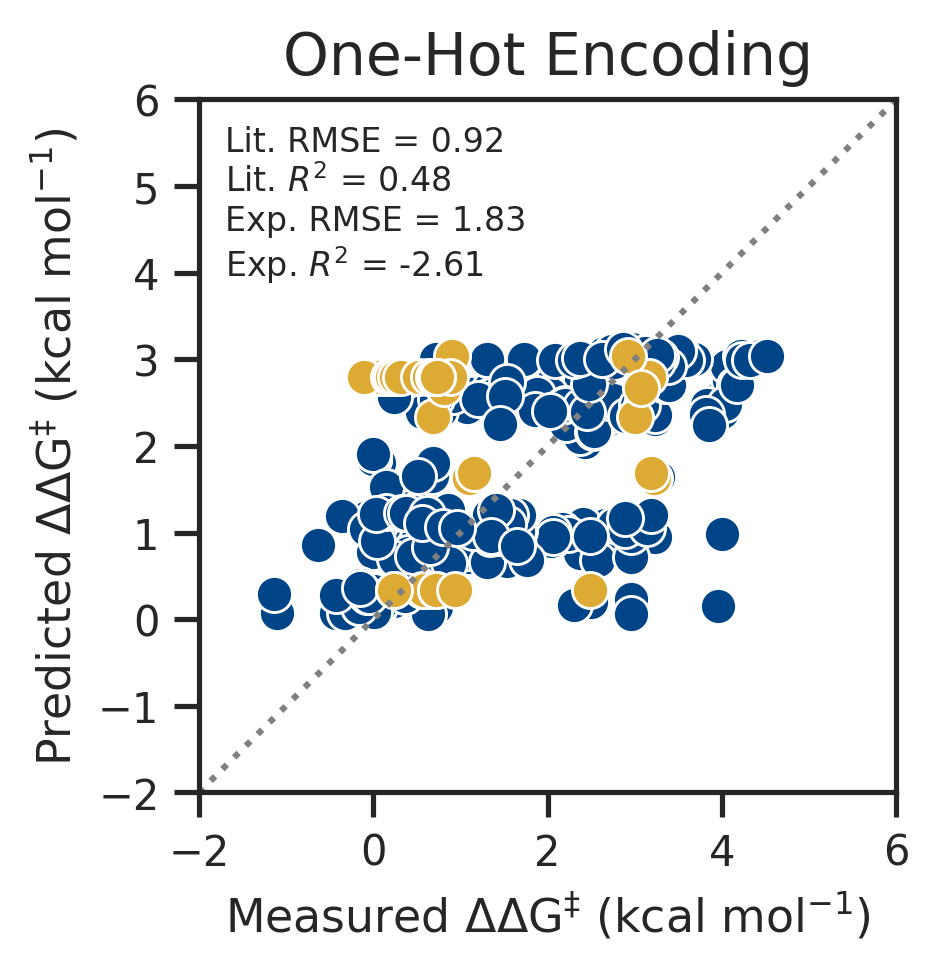

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

# Define colors and theme for plotting
colors: list[str] = ["#004488", "#DDAA33", "#BB5566", "#000000"]
color = sns.color_palette(colors)
plt.rcParams.update({"figure.figsize": (3, 3)})  # Set figure size
sns.set(rc={"figure.dpi": 300}, font_scale=1)  # Set DPI and font scale
sns.set_theme(style="ticks", palette=color)  # Set plot style and color palette
plt.tight_layout()  # Adjust layout

# Calculate performance metrics on cross-validated predictions
loco_r2: float = r2_score(y_lit, cv_preds)
loco_rmse: float = root_mean_squared_error(y_lit, cv_preds)
loco_mae: float = mean_absolute_error(y_lit, cv_preds)

exp_r2: float = r2_score(y_exp, exp_preds)
exp_rmse: float = root_mean_squared_error(y_exp, exp_preds)
exp_mae: float = mean_absolute_error(y_exp, exp_preds)

print(f"Experimental R2: {exp_r2:0.2f}")
print(f"Experimental RMSE: {exp_rmse:0.2f}")
print(f"Experimental MAE: {exp_mae:0.2f}")

# Create scatter plot of measured vs. predicted values
ax = sns.scatterplot(x=y_lit, y=cv_preds, label="LOCO", alpha=1, s=75)
sns.scatterplot(
    x=y_exp,
    y=exp_preds,
    label="Experimental",
    alpha=1,
    s=75,
    color=color[1],  # Use second color for experimental data
)

# Customize plot
plt.legend([], [], frameon=False)  # Hide legend
ax.set(
    xlabel=r"Measured $\Delta\Delta$G$^\ddag$ (kcal mol$^{-1}$)",
    ylabel=r"Predicted $\Delta\Delta$G$^\ddag$ (kcal mol$^{-1}$)",
)
ax.xaxis.label.set_fontsize(11)
ax.yaxis.label.set_fontsize(11)
ax.tick_params(axis="both", which="major", labelsize=10)
ax.set_xlim(-2, 6)
ax.set_ylim(-2, 6)

# Add identity line (y=x)
ax.plot(
    [0, 1],
    [0, 1],
    ":",
    color="grey",
    transform=ax.transAxes,
)

# Add title and text with metrics
ax.set_title("One-Hot Encoding", fontsize=14)
ax.text(
    -1.7,
    5.7,
    f"Lit. RMSE = {loco_rmse:0.2f}\nLit. $R^2$ = {loco_r2:0.2f}\n"
    f"Exp. RMSE = {exp_rmse:0.2f}\nExp. $R^2$ = {exp_r2:0.2f}",
    fontsize=8,
    horizontalalignment="left",
    verticalalignment="top",
    bbox=dict(facecolor="white", alpha=0.9),
)


# Save the plot as SVG
plt.savefig("LOCO_one_hot.svg", format="svg", bbox_inches="tight")
plt.show()  # Display the plot